# Clase 6 · Laboratorio — Regresión y Clasificación sobre Saber 11

**Trabajo en parejas · 90 min.**

En la pre-clase viste todos los modelos funcionando. En este laboratorio los implementarás tú con un target diferente: **predecir si un colegio es OFICIAL o NO OFICIAL** a partir de las características de los estudiantes y sus puntajes.

**Checkpoint del profesor a los 50 min** (después de la Tarea 3).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              confusion_matrix, ConfusionMatrixDisplay,
                              roc_auc_score, RocCurveDisplay,
                              mean_squared_error,mean_absolute_error, r2_score)
from sklearn.preprocessing import StandardScaler
import warnings; warnings.filterwarnings('ignore')


df = pd.read_csv("datos/saber11_muestra_500k.csv")
df["ESTRATO_NUM"] = df["FAMI_ESTRATOVIVIENDA"].str.extract(r"(\d+)").astype(float)
df["COLE_NAT_BIN"] = (df["COLE_NATURALEZA"] == "NO OFICIAL").astype(int)

FEATURES = ["PUNT_LECTURA_CRITICA","PUNT_MATEMATICAS","PUNT_C_NATURALES",
            "PUNT_SOCIALES_CIUDADANAS","PUNT_INGLES","ESTRATO_NUM"]


df_m = df[FEATURES + ["PUNT_GLOBAL","COLE_NAT_BIN"]].dropna()
print(f"Filas limpias: {len(df_m):,}")
print(f"Balance COLE_NAT_BIN: {df_m['COLE_NAT_BIN'].value_counts(normalize=True).round(3).to_dict()}")
print("(0=OFICIAL, 1=NO OFICIAL)")

Filas limpias: 449,081
Balance COLE_NAT_BIN: {0: 0.762, 1: 0.238}
(0=OFICIAL, 1=NO OFICIAL)


## Tarea 1 (15 min) — Regresión: predecir PUNT_MATEMATICAS

En la pre-clase predijiste PUNT_GLOBAL. Ahora predice **PUNT_MATEMATICAS** usando PUNT_LECTURA_CRITICA, PUNT_C_NATURALES, PUNT_SOCIALES_CIUDADANAS, PUNT_INGLES y ESTRATO_NUM.

1. Haz el split 80/20 con `random_state=42`.
2. Entrena una Regresión Lineal.
3. Calcula MSE, RMSE, MAE, R².
4. Grafica predicho vs real (scatter).
5. ¿Cuál feature tiene el coeficiente más alto? ¿Tiene sentido?

=== Métricas ===
MSE:  43.51  
MAE:  5.15  
RMSE: 6.60
R²:   0.6973


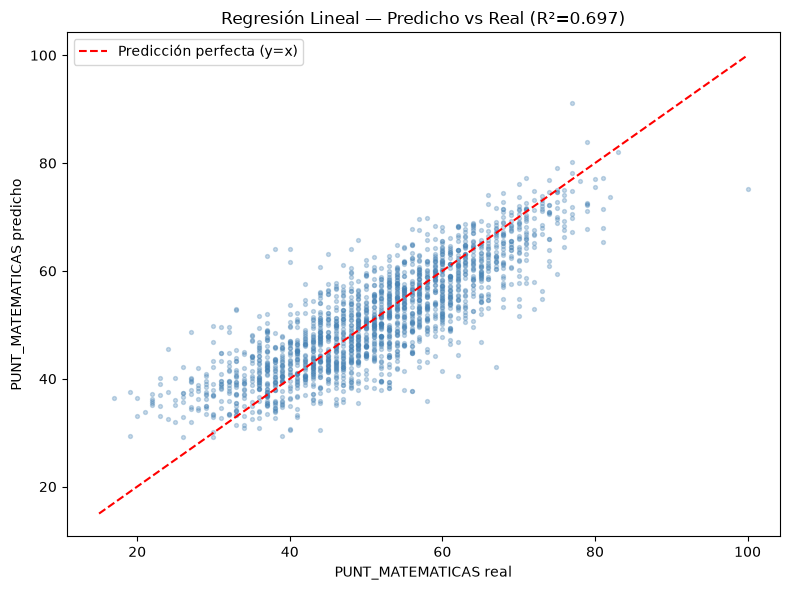


Coeficientes del modelo:
  PUNT_LECTURA_CRITICA               : +0.256
  PUNT_C_NATURALES                   : +0.538
  PUNT_SOCIALES_CIUDADANAS           : +0.105
  PUNT_INGLES                        : +0.102
  ESTRATO_NUM                        : -0.119


In [2]:
# 1: split
X_reg = df_m[["PUNT_LECTURA_CRITICA","PUNT_C_NATURALES","PUNT_SOCIALES_CIUDADANAS","PUNT_INGLES","ESTRATO_NUM"]]
y_reg = df_m["PUNT_MATEMATICAS"]
X_tr, X_te, y_tr, y_te = train_test_split(X_reg,y_reg, test_size=0.2, random_state=42)

# 2: entrenar Regresión Lineal
lr = LinearRegression()
lr.fit(X_tr,y_tr)

# 3: métricas
y_pred = lr.predict(X_te)
print("=== Métricas ===")
print(f"MSE:  {mean_squared_error(y_te,y_pred):.2f}  ")
print(f"MAE:  {mean_absolute_error(y_te, y_pred):.2f}  ")
print(f"RMSE: {np.sqrt(mean_squared_error(y_te, y_pred)):.2f}")
r2_lr = r2_score(y_te, y_pred)
print(f"R²:   {r2_lr:.4f}")

# 4: scatter predicho vs real
fig, ax = plt.subplots(figsize=(8, 6))
np.random.seed(42)
sample_idx = np.random.choice(len(y_te), 2000, replace=False)
ax.scatter(y_te.iloc[sample_idx], y_pred[sample_idx],
           alpha=0.3, s=8, color="steelblue")
lim = [y_te.min(), y_te.max()]
ax.plot(lim, lim, 'r--', linewidth=1.5, label="Predicción perfecta (y=x)")
ax.set_xlabel("PUNT_MATEMATICAS real")
ax.set_ylabel("PUNT_MATEMATICAS predicho")
ax.set_title(f"Regresión Lineal — Predicho vs Real (R²={r2_lr:.3f})")
ax.legend()
plt.tight_layout()
plt.show()
# 5: coeficientes
FEATURES_REG = ["PUNT_LECTURA_CRITICA","PUNT_C_NATURALES",
            "PUNT_SOCIALES_CIUDADANAS","PUNT_INGLES","ESTRATO_NUM"]

print("\nCoeficientes del modelo:")
for feat, coef in zip(FEATURES_REG, lr.coef_):
    print(f"  {feat:35s}: {coef:+.3f}")



La feature con el coeficiente más alto es PUNT_C_NATURALES, con un coeficiente de 0.538. Esto tiene sentido porque el desempeño en Ciencias Naturales está relacionado con el desempeño académico general del estudiante. El coeficiente positivo indica que, manteniendo las demás variables constantes, un aumento en el puntaje de Ciencias Naturales se relaciona con un aumento esperado en el puntaje de Matemáticas.

Algo curioso es que ESTRATO_NUM sale con coeficiente negativo (-0.119). Eso no significa que a mayor estrato peor le vaya en matemáticas, sino que el modelo ya tiene los otros cuatro puntajes y el estrato casi no aporta información extra sobre ellos. Además hay que tener cuidado al comparar coeficientes: los puntajes van de 0 a 100 pero el estrato va de 1 a 6, entonces no están en la misma escala.

## Tarea 2 (20 min) — Clasificar OFICIAL vs NO OFICIAL

Target: `COLE_NAT_BIN` (0=OFICIAL, 1=NO OFICIAL).

1. Haz el split 80/20 estratificado (`stratify=y_clf`).
2. Escala con `StandardScaler` (necesario para KNN y SVM).
3. Entrena los 4 modelos: Regresión Logística, KNN (k=5), SVM (kernel lineal sobre 20k filas), Árbol de Decisión (max_depth=5).
4. Para cada uno: calcula Accuracy, Precision, Recall, F1, AUC.
5. Muestra la matriz de confusión de Regresión Logística.

=== RESULTADOS DE LOS MODELOS ===
             Modelo  Accuracy  Precision  Recall     F1    AUC
Regresión Logística    0.7947     0.6889  0.2497 0.3666 0.7280
          KNN (k=5)    0.7821     0.5614  0.3850 0.4567 0.7384
       SVM (lineal)    0.7621     0.0000  0.0000 0.0000 0.6980
    Árbol (depth=5)    0.7998     0.6752  0.3056 0.4208 0.7405


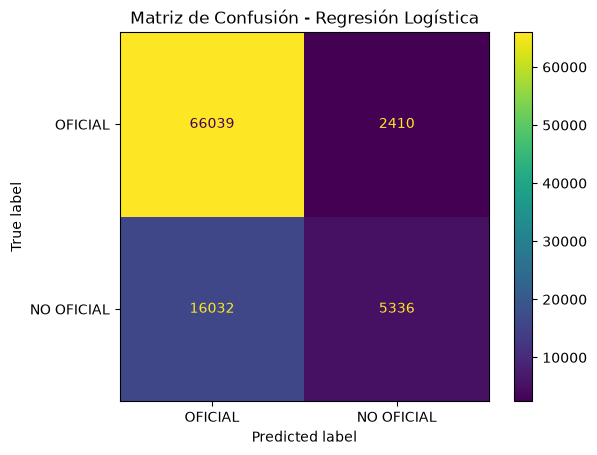

In [3]:
X_clf = df_m[FEATURES]
y_clf = df_m["COLE_NAT_BIN"]

# TODO 1: dividir 80/20 manteniendo la proporción de clases
X_tr_c, X_te_c, y_tr_c, y_te_c = train_test_split(
    X_clf,
    y_clf,
    test_size=0.2,
    random_state=42,
    stratify=y_clf
)

# TODO 2: escalar las variables
scaler = StandardScaler()

X_tr_sc = scaler.fit_transform(X_tr_c)
X_te_sc = scaler.transform(X_te_c)


# Función para evaluar los modelos
def evaluar_modelo(nombre, y_real, y_pred, y_proba):
    return {
        "Modelo": nombre,
        "Accuracy": round(accuracy_score(y_real, y_pred), 4),
        "Precision": round(precision_score(y_real, y_pred, zero_division=0), 4),
        "Recall": round(recall_score(y_real, y_pred, zero_division=0), 4),
        "F1": round(f1_score(y_real, y_pred, zero_division=0), 4),
        "AUC": round(roc_auc_score(y_real, y_proba), 4)
    }


resultados = []


logreg = LogisticRegression(
    max_iter=500,
    random_state=42
)

logreg.fit(X_tr_sc, y_tr_c)

pred_logreg = logreg.predict(X_te_sc)
proba_logreg = logreg.predict_proba(X_te_sc)[:, 1]

resultados.append(
    evaluar_modelo(
        "Regresión Logística",
        y_te_c,
        pred_logreg,
        proba_logreg
    )
)


knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_tr_sc, y_tr_c)

pred_knn = knn.predict(X_te_sc)
proba_knn = knn.predict_proba(X_te_sc)[:, 1]

resultados.append(
    evaluar_modelo(
        "KNN (k=5)",
        y_te_c,
        pred_knn,
        proba_knn
    )
)


n_svm = 20000

X_svm, _, y_svm, _ = train_test_split(
    X_tr_sc,
    y_tr_c,
    train_size=n_svm,
    random_state=42,
    stratify=y_tr_c
)

svm = SVC(
    kernel="linear",
    probability=True,
    random_state=42
)

svm.fit(X_svm, y_svm)

pred_svm = svm.predict(X_te_sc)
proba_svm = svm.predict_proba(X_te_sc)[:, 1]

resultados.append(
    evaluar_modelo(
        "SVM (lineal)",
        y_te_c,
        pred_svm,
        proba_svm
    )
)

tree = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

tree.fit(X_tr_c, y_tr_c)

pred_tree = tree.predict(X_te_c)
proba_tree = tree.predict_proba(X_te_c)[:, 1]

resultados.append(
    evaluar_modelo(
        "Árbol (depth=5)",
        y_te_c,
        pred_tree,
        proba_tree
    )
)

df_res = pd.DataFrame(resultados)

print("=== RESULTADOS DE LOS MODELOS ===")
print(df_res.to_string(index=False))


# Matriz de confusión de Regresión Logística

cm = confusion_matrix(y_te_c, pred_logreg)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["OFICIAL", "NO OFICIAL"]
)

disp.plot()

plt.title("Matriz de Confusión - Regresión Logística")
plt.show()

## Tarea 3 (15 min) — Comparación formal

1. Grafica las 4 matrices de confusión en un `plt.subplots(2,2)`.
2. Grafica las 4 curvas ROC en un mismo eje.
3. ¿Cuál modelo recomendarías para detectar colegios NO OFICIALES? Justifica usando las métricas (no solo accuracy).
4. El desbalance del dataset (70/30) ¿afectó los resultados? ¿Cómo lo notas en las métricas?

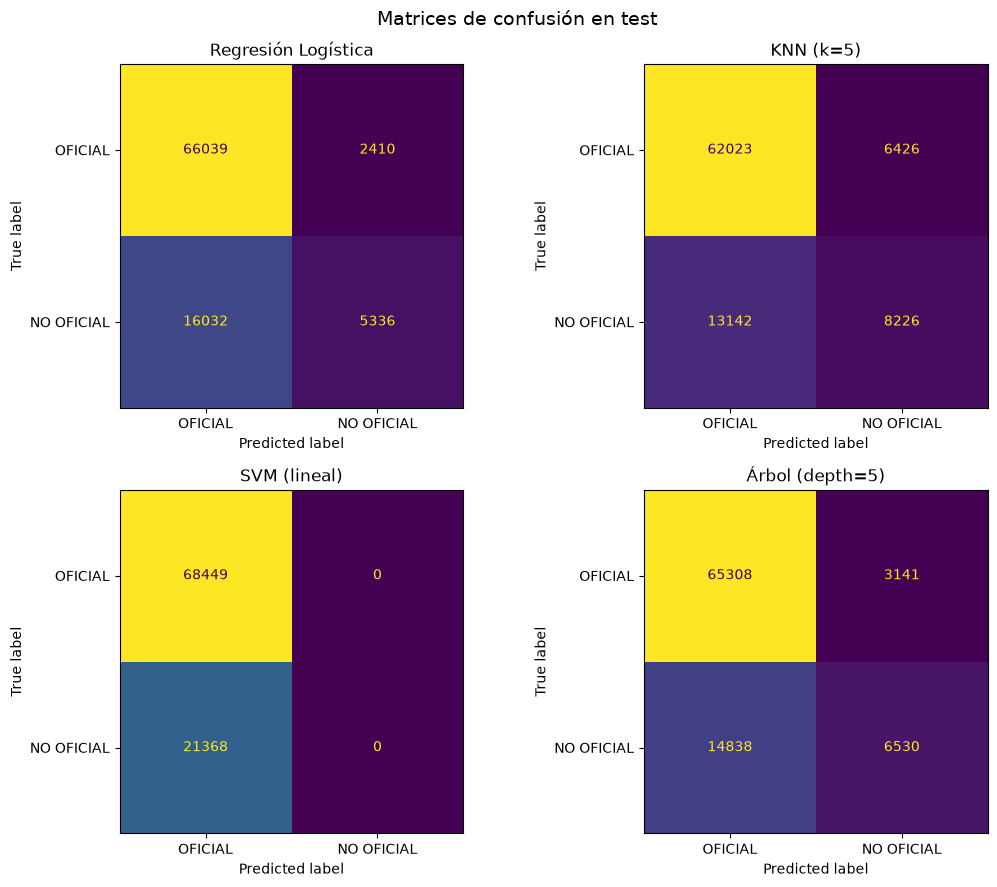

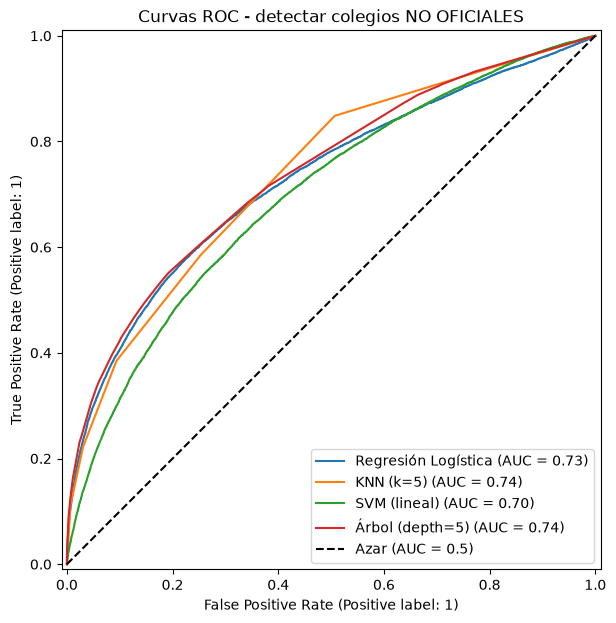

Accuracy si predecimos siempre OFICIAL: 0.7621
NO OFICIALES reales en test: 21,368 de 89,817

             Modelo  Accuracy  Precision  Recall     F1    AUC
          KNN (k=5)    0.7821     0.5614  0.3850 0.4567 0.7384
    Árbol (depth=5)    0.7998     0.6752  0.3056 0.4208 0.7405
Regresión Logística    0.7947     0.6889  0.2497 0.3666 0.7280
       SVM (lineal)    0.7621     0.0000  0.0000 0.0000 0.6980


In [4]:
# Guardamos las predicciones de la Tarea 2 en un diccionario para recorrerlas
modelos = {
    "Regresión Logística": (pred_logreg, proba_logreg),
    "KNN (k=5)": (pred_knn, proba_knn),
    "SVM (lineal)": (pred_svm, proba_svm),
    "Árbol (depth=5)": (pred_tree, proba_tree),
}

# TODO 1: 4 matrices de confusión subplots(2,2)
fig, axes = plt.subplots(2, 2, figsize=(11, 9))

for ax, (nombre, (pred, proba)) in zip(axes.flatten(), modelos.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_te_c,
        pred,
        display_labels=["OFICIAL", "NO OFICIAL"],
        values_format="d",
        colorbar=False,
        ax=ax
    )
    ax.set_title(nombre)

plt.suptitle("Matrices de confusión en test", fontsize=14)
plt.tight_layout()
plt.show()

# TODO 2: 4 curvas ROC
fig, ax = plt.subplots(figsize=(8, 7))

for nombre, (pred, proba) in modelos.items():
    RocCurveDisplay.from_predictions(y_te_c, proba, name=nombre, ax=ax)

ax.plot([0, 1], [0, 1], "k--", label="Azar (AUC = 0.5)")
ax.set_title("Curvas ROC - detectar colegios NO OFICIALES")
ax.legend(loc="lower right")
plt.show()

# Para responder las preguntas: comparar contra predecir siempre OFICIAL
acc_baseline = (y_te_c == 0).mean()
print(f"Accuracy si predecimos siempre OFICIAL: {acc_baseline:.4f}")
print(f"NO OFICIALES reales en test: {(y_te_c == 1).sum():,} de {len(y_te_c):,}\n")
print(df_res.sort_values("F1", ascending=False).to_string(index=False))

**Modelo recomendado y justificación:**

Para detectar colegios NO OFICIALES recomendamos **KNN (k=5)**. No es el de mejor accuracy (0.782 contra 0.800 del árbol), pero es el que mejor encuentra la clase que nos interesa: tiene el Recall más alto (0.385, detecta 8,226 de los 21,368 colegios no oficiales del test) y el F1 más alto (0.457). La Regresión Logística y el Árbol tienen mejor Precision (0.69 y 0.68), o sea que cuando dicen NO OFICIAL casi siempre aciertan, pero se les escapa la mayoría (Recall de 0.25 y 0.31). En AUC el Árbol (0.741) y KNN (0.738) quedan prácticamente empatados, entonces lo que decide es el Recall y el F1.

Si importara más no equivocarse cuando se dice NO OFICIAL, o la velocidad (KNN es lento al predecir porque compara cada punto contra todo el train), el **Árbol con depth=5** sería la segunda opción: tiene la mejor accuracy y AUC y además se puede interpretar.

El SVM lineal no sirve como quedó: predice OFICIAL para todos los colegios (Precision, Recall y F1 = 0). Su AUC de 0.698 muestra que sus probabilidades sí ordenan un poco los casos, pero con su frontera de decisión nunca llega a predecir la clase 1. También se nota que la curva ROC de KNN es de líneas rectas: con k=5 la probabilidad solo puede valer 0, 0.2, 0.4, 0.6, 0.8 o 1.

**¿El desbalance afectó?**

Sí. En nuestros datos la proporción no es 70/30 sino 76/24 (76.2% OFICIAL), así que un modelo que diga siempre OFICIAL ya saca 0.762 de accuracy. Eso es exactamente lo que hizo el SVM (0.7621 = baseline). Los demás apenas superan ese baseline: la mejor accuracy es 0.800 (Árbol), solo 3.8 puntos más.

Donde más se nota es en el Recall de NO OFICIAL: todos los modelos dejan escapar más de la mitad de los colegios no oficiales (Recall entre 0.25 y 0.39), mientras que con los oficiales casi no se equivocan (por ejemplo la logística solo marca mal 2,410 de 68,449). Como hay muchos más ejemplos de OFICIAL, los modelos aprenden a ir a lo seguro. Por eso aquí la accuracy engaña y hay que mirar Recall, F1 y AUC. Para mejorar se podría usar `class_weight="balanced"` en la logística, el SVM y el árbol, o bajar el umbral de decisión (por ejemplo 0.3 en vez de 0.5).

## ⏸ Checkpoint del profesor (10 min)

Discutimos:
- ¿Qué modelo tuvo mejor Recall para NO OFICIAL? ¿Por qué importa?
- Si el 70% de colegios son OFICIALES, predecir siempre OFICIAL daría Accuracy = 70%. ¿Qué obtuvieron sus modelos? ¿Superaron ese baseline?
- ¿Por qué la curva ROC del modelo perfecto sería un ángulo recto en la esquina superior izquierda?

## Tarea 4 (15 min) — Overfitting en el Árbol de Decisión

1. Entrena un Árbol con `max_depth` de 1 a 20.
2. Para cada depth: calcula accuracy en TRAIN y en TEST.
3. Grafica ambas curvas.
4. Identifica: ¿a qué depth empieza el overfitting? ¿Cuál es el mejor depth?

depth= 1  train=0.7621  test=0.7621  diferencia=0.0000
depth= 2  train=0.7965  test=0.7968  diferencia=-0.0003


depth= 3  train=0.7965  test=0.7968  diferencia=-0.0003
depth= 4  train=0.7993  test=0.7987  diferencia=0.0005


depth= 5  train=0.8002  test=0.7998  diferencia=0.0004


depth= 6  train=0.8009  test=0.8002  diferencia=0.0007


depth= 7  train=0.8014  test=0.8001  diferencia=0.0013


...

depth=16  train=0.8305  test=0.8000  diferencia=0.0306


depth=17  train=0.8382  test=0.8006  diferencia=0.0376


depth=18  train=0.8471  test=0.8001  diferencia=0.0470


depth=19  train=0.8574  test=0.8025  diferencia=0.0549


depth=20  train=0.8683  test=0.8024  diferencia=0.0658


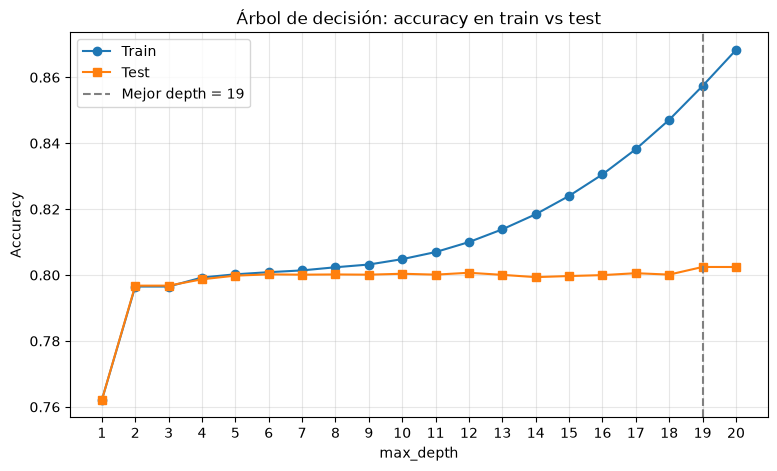

Mejor depth (mayor test accuracy): 19 (test accuracy = 0.8025)


In [5]:
# TODO: curva overfitting
depths = range(1, 21)
scores_tr, scores_te = [], []
for d in depths:
    arbol = DecisionTreeClassifier(max_depth=d, random_state=42)
    arbol.fit(X_tr_c, y_tr_c)
    scores_tr.append(accuracy_score(y_tr_c, arbol.predict(X_tr_c)))
    scores_te.append(accuracy_score(y_te_c, arbol.predict(X_te_c)))
    print(f"depth={d:2d}  train={scores_tr[-1]:.4f}  test={scores_te[-1]:.4f}  "
          f"diferencia={scores_tr[-1] - scores_te[-1]:.4f}")

# TODO: graficar
mejor_depth = depths[np.argmax(scores_te)]

plt.figure(figsize=(9, 5))
plt.plot(depths, scores_tr, "o-", label="Train")
plt.plot(depths, scores_te, "s-", label="Test")
plt.axvline(mejor_depth, color="gray", linestyle="--", label=f"Mejor depth = {mejor_depth}")
plt.xlabel("max_depth")
plt.ylabel("Accuracy")
plt.title("Árbol de decisión: accuracy en train vs test")
plt.xticks(list(depths))
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(f"Mejor depth (mayor test accuracy): {mejor_depth} (test accuracy = {max(scores_te):.4f})")

**¿A qué depth empieza el overfitting?**

Hasta depth 8 las dos curvas van casi juntas (la diferencia entre train y test es menor a 0.25 puntos). Desde depth 10 el accuracy de train sigue subiendo (0.805 en depth 10 hasta 0.868 en depth 20) pero el de test se queda plano alrededor de 0.800, y la brecha crece de 0.4 a 6.6 puntos. Ahí el árbol empieza a memorizar los datos de entrenamiento en vez de aprender patrones que sirvan para datos nuevos. Diríamos que el overfitting empieza alrededor de **depth 10** y ya es claro desde depth 12-13, donde la diferencia pasa de 1 punto.

**¿Cuál es el mejor depth?**

Si solo miramos el número, el mayor test accuracy es en depth 19 (0.8025). Pero la diferencia con depth 6 (0.8002) es de apenas 0.23 puntos, y el árbol de depth 19 tiene una brecha train-test de 5.5 puntos y es muchísimo más complejo. Por eso escogeríamos **depth 6** (el depth 5 de la Tarea 2 da casi lo mismo, 0.7998): prácticamente la misma accuracy en test, sin overfitting y mucho más fácil de interpretar. También llama la atención que con depth 2 ya se llega a 0.797, o sea que casi todo lo que el árbol puede aprender lo aprende en los primeros niveles.

Una aclaración: escoger el depth mirando el test no es lo ideal, porque el test debería usarse solo al final. Lo correcto sería usar un conjunto de validación o validación cruzada, pero aquí usamos el test porque así lo pide el ejercicio.

## Tarea 5 (15 min) — Primer modelo sobre el dataset del P2/3

1. Carga el dataset limpio de tu proyecto (`datos_limpios.parquet` si existe, o el CSV original).
2. Define X (features) e y (variable objetivo del P2/3).
3. Haz el split 80/20.
4. Entrena UN modelo (el que consideres más adecuado para tu tipo de problema).
5. Reporta las métricas principales.

Este es tu **modelo baseline** para el P2/3. Los siguientes modelos los entrenarás en casa.

In [6]:
from pathlib import Path

# TODO: cargar dataset del proyecto
# No tenemos un parquet limpio del proyecto, así que leemos los 8 .xlsx originales
# de la DIJIN igual que en la fase B del P1 (el encabezado real está en la fila 11)
CARPETA_PROYECTO = Path("..", "Grupo-7-p-1", "Grupo-7-p1", "datos")

marcos = []
for archivo in sorted(CARPETA_PROYECTO.glob("*.xlsx")):
    datos = pd.read_excel(archivo, header=10)
    datos.columns = [c.strip() for c in datos.columns]
    datos["TIPO_DELITO"] = archivo.stem.removesuffix("2025").strip().upper()
    marcos.append(datos)

delitos = pd.concat(marcos, ignore_index=True)
delitos = delitos.dropna(subset=["CODIGO DANE"])  # quita las filas de pie de página
delitos["FECHA HECHO"] = pd.to_datetime(delitos["FECHA HECHO"], format="%d/%m/%Y")
delitos["MES"] = delitos["FECHA HECHO"].dt.month
delitos["CODIGO DANE"] = delitos["CODIGO DANE"].astype("int64").astype(str)
print(f"Casos cargados: {len(delitos):,}")

# CANTIDAD siempre vale 1 (una fila = un caso), entonces como dijimos en el lab 1
# agrupamos por municipio x delito x mes para tener un conteo que sí varíe
casos = (
    delitos.groupby(["CODIGO DANE", "DEPARTAMENTO", "TIPO_DELITO", "MES"])["CANTIDAD"]
    .sum()
    .reset_index(name="CASOS_MES")
)

# Feature extra: casos del mismo municipio y delito en el mes anterior (0 si no hubo)
mes_anterior = casos[["CODIGO DANE", "TIPO_DELITO", "MES", "CASOS_MES"]].copy()
mes_anterior["MES"] = mes_anterior["MES"] + 1
mes_anterior = mes_anterior.rename(columns={"CASOS_MES": "CASOS_MES_ANTERIOR"})

casos = casos.merge(mes_anterior, on=["CODIGO DANE", "TIPO_DELITO", "MES"], how="left")
casos["CASOS_MES_ANTERIOR"] = casos["CASOS_MES_ANTERIOR"].fillna(0)

# Enero no tiene mes anterior (no tenemos datos de 2024), así que se quita
casos = casos[casos["MES"] > 1]
print(f"Filas (municipio x delito x mes): {len(casos):,}")
print(casos["CASOS_MES"].describe().round(2))

# TODO: definir X e y
X_p = pd.get_dummies(
    casos[["MES", "CASOS_MES_ANTERIOR", "TIPO_DELITO", "DEPARTAMENTO"]],
    columns=["TIPO_DELITO", "DEPARTAMENTO"],
    dtype=int
)
y_p = casos["CASOS_MES"]

# TODO: split
X_tr_p, X_te_p, y_tr_p, y_te_p = train_test_split(X_p, y_p, test_size=0.2, random_state=42)

# TODO: entrenar un modelo
rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_tr_p, y_tr_p)
y_pred_p = rf.predict(X_te_p)

# TODO: métricas
print("\n=== Random Forest (baseline P2/3) ===")
print(f"MSE:  {mean_squared_error(y_te_p, y_pred_p):.2f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_te_p, y_pred_p)):.2f}")
print(f"MAE:  {mean_absolute_error(y_te_p, y_pred_p):.2f}")
print(f"R²:   {r2_score(y_te_p, y_pred_p):.4f}")

# ¿Le gana a simplemente repetir lo que pasó el mes anterior?
y_ingenuo = X_te_p["CASOS_MES_ANTERIOR"]
print("\n=== Predicción ingenua (mismo valor del mes anterior) ===")
print(f"RMSE: {np.sqrt(mean_squared_error(y_te_p, y_ingenuo)):.2f}")
print(f"MAE:  {mean_absolute_error(y_te_p, y_ingenuo):.2f}")
print(f"R²:   {r2_score(y_te_p, y_ingenuo):.4f}")

importancias = pd.Series(rf.feature_importances_, index=X_p.columns).sort_values(ascending=False)
print("\nFeatures más importantes:")
print(importancias.head(5).round(3).to_string())

Casos cargados: 480,091
Filas (municipio x delito x mes): 25,185
count    25185.00
mean        17.52
std        248.81
min          1.00
25%          1.00
50%          2.00
75%          4.00
max      12724.00
Name: CASOS_MES, dtype: float64



=== Random Forest (baseline P2/3) ===
MSE:  3373.87
RMSE: 58.09
MAE:  4.25
R²:   0.9506

=== Predicción ingenua (mismo valor del mes anterior) ===
RMSE: 19.78
MAE:  3.55
R²:   0.9943

Features más importantes:
CASOS_MES_ANTERIOR                     0.956
MES                                    0.025
TIPO_DELITO_HURTO A PERSONAS           0.010
TIPO_DELITO_VIOLENCIA INTRAFAMILIAR    0.008
DEPARTAMENTO_CUNDINAMARCA              0.001


**Tipo de problema de mi proyecto:** Regresión

**Variable objetivo:** `CASOS_MES`, el número de casos de un tipo de delito en un municipio durante un mes de 2025. El dataset de la DIJIN trae una fila por caso y `CANTIDAD` siempre vale 1, por eso agrupamos por municipio (código DANE) x tipo de delito x mes, como lo habíamos planteado en el lab 1. Quedan 25,185 filas (sin enero, porque no tiene mes anterior).

**Modelo elegido como baseline:** `RandomForestRegressor` (100 árboles, `random_state=42`) con las features `MES`, `CASOS_MES_ANTERIOR`, y `TIPO_DELITO` y `DEPARTAMENTO` en one-hot. Escogimos Random Forest porque la variable está muy sesgada (la mediana es 2 casos, pero Bogotá llega a 12,724 hurtos a personas en octubre) y no esperamos que la relación sea lineal.

**Métricas obtenidas** (test, 20% de las filas):

| Modelo | RMSE | MAE | R² |
|---|---|---|---|
| Random Forest | 58.09 | 4.25 | 0.9506 |
| Ingenuo (repetir el valor del mes anterior) | 19.78 | 3.55 | 0.9943 |

**Observaciones:**
- El R² de 0.95 se ve muy bueno, pero casi todo sale de `CASOS_MES_ANTERIOR` (importancia de 0.956). Antes probamos sin esa variable y el R² daba prácticamente 0, porque solo con mes, delito y departamento el modelo no sabe si el municipio es grande o pequeño.
- El Random Forest **no le gana** a la predicción ingenua de "este mes habrá lo mismo que el mes pasado". El RMSE tan alto comparado con el MAE (58 contra 4) viene de los pocos municipios con miles de casos como Bogotá: hay muy pocos ejemplos así y los árboles no logran predecir valores tan extremos.
- Limitación: solo hay filas para los meses con al menos un caso, entonces el modelo nunca ve meses con 0 casos.
- Para el P2/3 (en casa): hacer un split temporal (entrenar con febrero a octubre y probar con noviembre y diciembre) en vez de uno aleatorio, predecir el logaritmo de los casos para que Bogotá no pese tanto, y agregar más rezagos o el promedio histórico del municipio. La meta mínima es superar al modelo ingenuo.

## Entrega

Guarda este notebook completado.
**Nombre:** `02_laboratorio_apellido1_apellido2.ipynb`
**Sube a:** Moodle → Clase 6 → Laboratorio.